In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
import xarray as xr
import rioxarray as rxr
from tqdm import tqdm
import glob
from scipy import signal
from scipy import stats
from numpy.lib.stride_tricks import sliding_window_view
from obspy.signal.filter import highpass, bandpass, lowpass
from obspy.signal.invsim import cosine_taper
from scipy.signal import spectrogram, detrend
from obspy.signal.trigger import classic_sta_lta, plot_trigger,trigger_onset
import obspy
from itertools import combinations
from sympy import plot
import os


In [2]:
plot_dir = '../../plots/gridsearch/'
if not os.path.exists(plot_dir):
    os.makedirs(plot_dir)

In [3]:
data_dir = '../../data/gridsearch/'
if not os.path.exists(data_dir):
    os.makedirs(data_dir)

## Importing data

In [4]:
ncfiles = glob.glob('/mnt/ICELAND_2024/GUNNUVHER/FBG/LowFreqSampling/aligned_nc_converted/FBG_*nc')#+glob.glob('/mnt/ICELAND_2024/GUNNUVHER/FBG/LowFreqSampling/aligned_nc_converted/FBG_2025.02*nc')
ncfiles.sort()
for i, file in enumerate(tqdm(ncfiles)) : 
    ds = xr.open_dataset(file)
    ds = ds.drop_vars(['relative_Time', 'Temperature_calibration','Strain_calibration'])
    #ds = preprocess(ds)
    ds = ds.sel(Channel=2)
    if i == 0 :
        dsch_hstrain = ds.copy()
        continue
    dsch_hstrain = xr.concat([dsch_hstrain, ds], dim='Time')

100%|██████████| 347/347 [01:19<00:00,  4.38it/s]


In [5]:
rng = np.arange(dsch_hstrain.Time.values[0], dsch_hstrain.Time.values[-1], 2, dtype='datetime64[s]')

In [6]:
dsch_hstrain = dsch_hstrain.sortby('Time')
dsch_hstrain = dsch_hstrain.drop_duplicates('Time')

## Look to october; 3-hour signals

### Preprocessing functions

In [7]:
def _detrend_ufunc(x) :
    med = np.nanmedian(x, axis=1).reshape(-1,1)
    dtrend = x - med
    dtrend = np.where(dtrend > 1, np.nan, dtrend)
    return dtrend

def detrend_signal(x) :
    return xr.apply_ufunc(_detrend_ufunc, x)

In [8]:
def centroid(x, y):
    return np.sum(x * y) / np.sum(y)

### Preprocessing

In [9]:
dtrend_october = detrend_signal(dsch_hstrain.sel(Time=slice('2024-10-19', '2024-10-25'), FBG=slice(0,6)))

In [10]:
dsch_hstrain = dsch_hstrain.reindex({'Time': rng}, method='nearest', tolerance=np.timedelta64(2, 's'))

/tmp/ipykernel_430133/3606962735.py:1: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  dsch_hstrain = dsch_hstrain.reindex({'Time': rng}, method='nearest', tolerance=np.timedelta64(2, 's'))


### Strain-rate

In [11]:
#dtrend_october = dtrend_october.sel(Time=slice('2024-10-18T11', '2024-10-24'))
grad = np.gradient(dtrend_october.Wavelength_nm, axis=1)

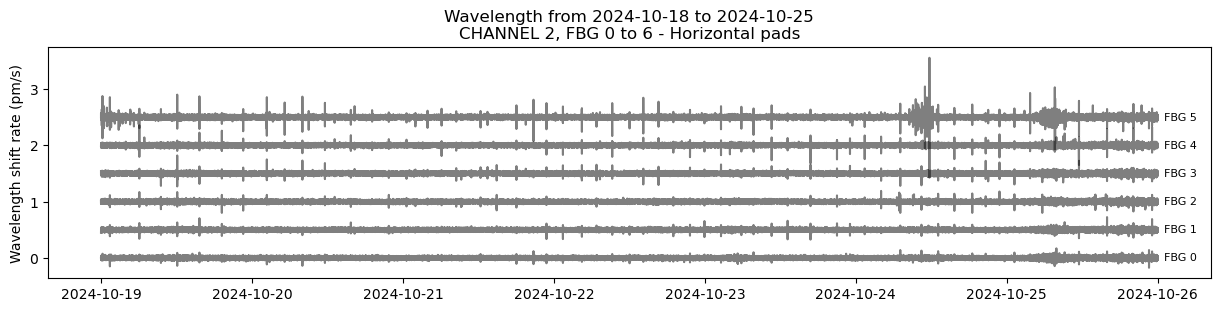

In [12]:
%matplotlib inline
#filt_grad = np.zeros_like(grad)
#for i in range(grad.shape[1]) :
#    filt_grad[:,i] = signal.medfilt(grad[:,i], kernel_size=3)
plt.figure(figsize=(15,3))
for i in range(grad.shape[0]):
    plt.plot(dtrend_october.Time, grad[i,:]*1000+ i*0.5, color='k', alpha=0.5)
    plt.text(dtrend_october.Time.values[-1] + pd.Timedelta(seconds=60*60), i*0.5, f'FBG {i}', va='center', ha='left', fontsize=8)
plt.ylabel('Wavelength shift rate (pm/s)')
#plt.fill_betweenx(np.arange(-0.5, 4.5, 1), np.datetime64('2024-10-19T11'), np.datetime64('2024-10-24T08'), color='orange', alpha=0.3)
plt.title('Wavelength from 2024-10-18 to 2024-10-25\nCHANNEL 2, FBG 0 to 6 - Horizontal pads')
plt.show()

### Cross-correlation between strain-pads

In [13]:
ndiv = 7*24*4
nsamp = grad.shape[1]//ndiv
plot = False

combi = combinations(range(grad.shape[0]), 2)
all_centroid_lags = []
for c in combi :
    _lags = []
    _corr_2d = [] 
    _pearson_r = []
    for i in range(ndiv) :
        trace_1 = grad[c[0],nsamp*i:nsamp*(i+1)]
        trace_2 = grad[c[1],nsamp*i:nsamp*(i+1)]

        correlation = signal.correlate(trace_1, trace_2, mode="full")
        lags = signal.correlation_lags(len(trace_1), len(trace_2), mode="full")/.5
        _corr_2d.append(correlation/np.max(correlation))
        lag = lags[np.argmax(correlation)]
        _lags.append(lag)
        _pearson_r.append(stats.pearsonr(trace_1, trace_2)[0])
    print(_pearson_r)

    med = np.mean(np.array(_corr_2d)[np.array(_pearson_r) > 0.5], axis=0)
    centroid_lag = centroid(np.array(lags)[np.argmax(med)-2:np.argmax(med)+3], med[np.argmax(med)-2:np.argmax(med)+3]+np.min(med[np.argmax(med)-2:np.argmax(med)+3]))
    all_centroid_lags.append(centroid_lag)
    if plot:
        fig, ax = plt.subplots(figsize=(10,7), nrows=2)    
        ax[0].imshow(_corr_2d, aspect='auto', interpolation='none', cmap='seismic', extent=[min(lags), max(lags), 0, ndiv], vmin=np.nanpercentile(_corr_2d, .1), vmax=np.nanpercentile(_corr_2d, 99.9))
        ax[0].scatter(np.array(lags)[np.argmax(np.array(_corr_2d), axis=1)], np.arange(ndiv), color='green',marker='x', s=10, label='Max correlation')
        ax[0].set_xlabel('Lag')
        ax[0].set_ylabel('Sample')
        ax[0].set_title(f'Cross-correlation of FBG {c[0]} and FBG {c[1]}')
        ax[0].set_xlim(-50,50)
        
        ax[1].plot(np.array(lags),med, color='k', marker="o")
        ax[1].fill_between(np.array(lags), med - np.std(np.array(_corr_2d), axis=0), med + np.std(np.array(_corr_2d), axis=0), color='grey', alpha=0.1, label='Std deviation')
        ax[1].plot(np.array(lags)[np.argmax(med)-2:np.argmax(med)+3], med[np.argmax(med)-2:np.argmax(med)+3], color='r', marker="o", ls='--', label='Centroid')
        ax[1].axvline(centroid_lag, color='r', linestyle='--', label=f'Centroid lag: {centroid_lag:.2f}')
        ax[1].legend()
        ax[1].set_xlabel('Lag')
        ax[1].set_ylabel('Mean Cross-correlation')
        ax[1].set_title(f'Cross-correlation of FBG {c[0]} and FBG {c[1]}')
        ax[1].set_xlim(-50,50)
        plt.tight_layout()
        plt.show()

[0.22667321049992195, 0.2088399259379114, 0.2430438060914556, 0.12560927488980247, 0.2999943322665837, 0.27376605955197025, 0.18209967902351443, 0.13670813878051105, -0.012823282309248583, 0.0778072495094792, 0.03965980499185736, 0.09605042162773929, 0.10297988836985755, 0.1765472107087719, 0.10452838652234626, 0.1688585965789179, 0.03710210697942955, 0.1420977955290273, 0.051360034071563164, 0.10194444604095747, 0.17595839340572078, 0.11064295768716696, 0.09268920150711173, 0.05792750756416262, 0.3726408177342738, 0.19737920340126539, 0.006806611194953989, 0.08619470183008485, 0.13631376406169082, 0.2451423087587759, 0.08013414368873245, 0.21403414623242994, 0.05680469788678684, 0.2877675672718768, 0.2885889336506545, 0.23138462632206047, 0.34914113157939286, 0.2854354436084441, 0.35545681068673146, 0.15202378183951595, 0.24903261716262676, 0.17576804676012414, 0.2588984095163013, 0.277792850233533, 0.28944668651551386, 0.30080635132938083, 0.4016196788185984, 0.35546213046330916, 0.4

## Localise

In [14]:
import utm
import itertools as it
from tqdm import tqdm

### Functions

In [15]:
def TimeGrid_stations(StatA, StatB, vel, extent=(-50,50),res=1000, plot=False):
    '''
    Create a grid of distances between two stations
    
    extent : tuple
        (xmin, xmax, ymin, ymax)
    res : int
        resolution of the grid

    '''
    vel = vel
    idxGridX = np.array([np.linspace(extent[0], extent[1], res),]*res)
    idxGridY = np.array([np.linspace(extent[0], extent[1], res),]*res).T


    distA = np.sqrt((idxGridX - StatA[0])**2 + (idxGridY - StatA[1])**2)
    distB = np.sqrt((idxGridX - StatB[0])**2 + (idxGridY - StatB[1])**2)

    TimeA = distA / vel
    TimeB = distB / vel

    if plot:
        fig, ax = plt.subplots(3, 2, figsize=(10, 10))
        idxX = ax[0,0].imshow(idxGridX, cmap='jet', origin='lower', extent=[extent[0], extent[1], extent[0], extent[1]])
        idxY = ax[0,1].imshow(idxGridY, cmap='jet', origin='lower', extent=[extent[0], extent[1], extent[0], extent[1]])
        da = ax[1,0].imshow(distA, cmap='jet', origin='lower', extent=[extent[0], extent[1], extent[0], extent[1]])
        db = ax[1,1].imshow(distB, cmap='jet', origin='lower', extent=[extent[0], extent[1], extent[0], extent[1]])
        ta = ax[2,0].imshow(TimeA, cmap='jet', origin='lower', extent=[extent[0], extent[1], extent[0], extent[1]])
        tb = ax[2,1].imshow(TimeB, cmap='jet', origin='lower', extent=[extent[0], extent[1], extent[0], extent[1]])
        ax[1,0].scatter(StatA[0], StatA[1], color='r', marker='x', label='Station A')
        ax[1,0].scatter(StatB[0], StatB[1], color='g', marker='x', label='Station B')
        ax[1,1].scatter(StatA[0], StatA[1], color='r', marker='x', label='Station A')
        ax[1,1].scatter(StatB[0], StatB[1], color='g', marker='x', label='Station B')
        ax[2,0].scatter(StatA[0], StatA[1], color='r', marker='x', label='Station A')
        ax[2,0].scatter(StatB[0], StatB[1], color='g', marker='x', label='Station B')
        ax[2,1].scatter(StatA[0], StatA[1], color='r', marker='x', label='Station A')
        ax[2,1].scatter(StatB[0], StatB[1], color='g', marker='x', label='Station B')
        ax[0,0].set_title('X grid')
        ax[0,1].set_title('Y grid')
        ax[1,0].set_title('Distance to Station A')
        ax[1,1].set_title('Distance to Station B')
        ax[2,0].set_title('Time to Station A')
        ax[2,1].set_title('Time to Station B')
        fig.colorbar(idxX, ax=ax[0,0])
        fig.colorbar(idxY, ax=ax[0,1])
        fig.colorbar(da, ax=ax[1,0])
        fig.colorbar(db, ax=ax[1,1])
        fig.colorbar(ta, ax=ax[2,0])
        fig.colorbar(tb, ax=ax[2,1])
        fig.show()
        
    Diff = TimeA - TimeB

    return Diff

In [16]:
def gridsearch(TraceA, TraceB, StatA, StatB, vel, extent=(-50,50), round=1 , res=1000, plot=False):
    '''
    Grid-search between two stations
    
    dataA, dataB : obspy.trace
        data from two stations
    vel : float
        velocity of the wave
    extent : tuple
        (xmin, xmax, ymin, ymax)
    res : int
        resolution of the grid
    plot : bool
        plot the grid
    
    '''
    corr = signal.correlate(TraceA, TraceB, mode='full', method='auto')
    #corr_time = np.linspace(-TraceA.stats.delta * len(corr) / 2, TraceA.stats.delta * len(corr) / 2, len(corr))
    lags = signal.correlation_lags(len(TraceA), len(TraceB), mode="full")/.5
    corr_time = lags
    corr_time_interp = np.arange(-5, 5, .01)
    corr_interp = np.interp(corr_time_interp, corr_time, corr)
    hilb = signal.hilbert(corr_interp, N=len(corr_interp))
    #inst_phase = np.unwrap(np.angle(hilb))#inst phase
    round_cc_time, idx = np.unique(np.round(corr_time_interp, round), return_index=True)
    round_cc = np.abs(hilb)[idx]
    
    Diff = TimeGrid_stations(StatA, StatB, vel, extent=extent, res=res, plot=plot)
    Diff = np.round(Diff, round)
    Beamform = np.full((res,res), np.nan)
    for i, t in enumerate(round_cc_time):
        idx1, idx2 = np.where(Diff == t)
        if len(idx1) < 0 | len(idx2) < 0:
            continue
        Beamform[idx1, idx2] = round_cc[i]
    
    return Beamform

In [17]:
def gridsearch_plot(x,y, idx, ALL_Beamform,idEQ):
    fig, ax = plt.subplots(1,2, figsize=(10,5))
    ax[0].imshow(np.sum(ALL_Beamform, axis=2), cmap='viridis', extent=(-10,30,-10,30), origin='lower')
    ax[1].imshow(np.prod(ALL_Beamform, axis=2), cmap='viridis', extent=(-10,30,-10,30), origin='lower')
    #plt.colorbar()
    ax[0].scatter(x, y, c='k', marker='+')
    ax[1].scatter(x[idx], y[idx], c='r', marker='x')
    ax[1].scatter(x, y, c='k', marker='+')
    ax[0].scatter(x[idx], y[idx], c='r', marker='x')

    ax[0].set_title('Sum of the gridsearch')
    ax[1].set_title('Product of the gridsearch')

    ax[0].set_xlabel('X (km)')
    ax[0].set_ylabel('Y (km)')
    ax[1].set_xlabel('X (km)')
    ax[1].set_ylabel('Y (km)')
    plt.savefig('./beamplots/Beamform_%s_%i.png'%(idEQ, len(x[idx])), bbox_inches='tight')
    plt.close()

### Parameters
set coordinates of the strain-pads and the grid resolution

In [18]:
#station_locations = {"FBG": [-17.584581, 64.441139, 1549], "20756": [-17.5483, 64.534529, 1703], "20759": [-17.635169, 64.515366, 1586], "20746": [-17.647782, 64.392455, 1415], "20753": [-17.569304, 64.493268, 1617], "20768": [-17.48582, 64.46339, 1650], "20760": [-17.666423, 64.474981, 1532], "20732": [-17.473058, 64.508453, 1683]}
station_locations = {"FBG1": [-22.6840418280941, 63.8221780077185, 10], "FBG2": [-22.6841633977408,63.8221006376023, 10], "FBG3": [-22.6844301043159, 63.8219698466827, 10], "FBG4": [-22.6845621550886, 63.82189879442090, 10],
                      "FBG5": [-22.6846781072771, 63.8218402416911, 10], "FBG6": [-22.6847612182528, 63.8217597962565, 10], "FBG7": [-22.6848294436807, 63.8216601968287, 10]}
res = 10

In [19]:
Stations, LAT, LON = [], [], []
for ss in station_locations.keys():
    Stations.append(ss)
    LAT.append(station_locations[ss][0])
    LON.append(station_locations[ss][1])
Stations = np.array(Stations)

x, y,  = utm.from_latlon(np.array(LON),np.array(LAT), force_zone_number=27, force_zone_letter='V')[:2]

x, y = (x-x.min()), (y-y.min())

In [20]:
x, y

(array([40.2810966 , 34.07125055, 20.562121  , 13.85497611,  7.97677001,
         3.6502955 ,  0.        ]),
 array([56.66155354, 48.20032749, 33.97648599, 26.23272407, 19.86052086,
        11.00680871,  0.        ]))

In [21]:
#ndiv = 7*6
#nsamp = grad.shape[1]//ndiv


combi = combinations(range(grad.shape[0]), 2)

pair_beams = []
for c in tqdm(combi) :  
    all_Beamform = [] 
    for i in range(ndiv) :
        trace_1 = grad[c[0],nsamp*i:nsamp*(i+1)]
        trace_2 = grad[c[1],nsamp*i:nsamp*(i+1)]
        beam = gridsearch(trace_1, trace_2, (x[c[0]], y[c[0]]), (x[c[1]], y[c[1]]), 300, extent=(-1000,1000), 
                           res=100, plot=False, round=2)
        all_Beamform.append(beam)
    pair_beams.append(np.sum((np.array(all_Beamform)), axis=0))


15it [03:07, 12.47s/it]


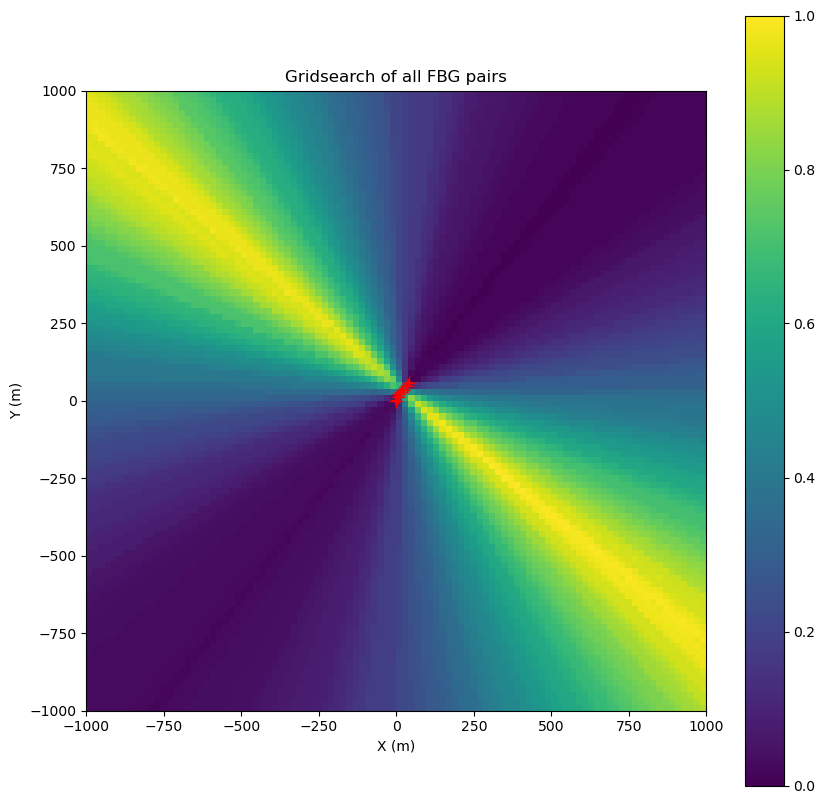

In [22]:
combi = combinations(range(grad.shape[0]), 2)
plt.figure(figsize=(10,10))
plt.imshow(np.sum(np.array(pair_beams), axis=0), cmap='viridis', extent=(-1000,1000,-1000,1000), origin='lower', alpha=1)
#plt.xlim(-250,250)
#plt.ylim(-250,250)
plt.plot(x, y, 'r+', markersize=10)
plt.scatter(x, y, c='r', marker='+')
plt.title('Gridsearch of all FBG pairs')
plt.xlabel('X (m)')
plt.ylabel('Y (m)')
plt.colorbar()
plt.show()

### Save results to tiff

In [23]:
xss, yss,  = utm.from_latlon(np.array(LON),np.array(LAT), force_zone_number=27, force_zone_letter='V')[:2]

In [24]:
y_coords = np.linspace(yss.min() + (-1000), yss.min() + (1000), 100)
x_coords = np.linspace(xss.min() + (-1000), xss.min() + (1000), 100)

In [25]:
dageo = xr.DataArray(data = np.sum(np.array(pair_beams), axis=0),
                     coords = {'y': y_coords, 'x': x_coords})

In [26]:
dageo = dageo.rio.write_crs("EPSG:32627")

ERROR 1: PROJ: internal_proj_create_from_database: /home/geophysic/anaconda3/envs/ghice/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 2 whereas a number >= 3 is expected. It comes from another PROJ installation.


In [27]:
dageo.rio.to_raster('./beamforming_sum.tif')

In [28]:
SXX = []
fs = np.mean(np.diff(dtrend_october.Time.values).astype('timedelta64[s]').astype(float))
for i in range(grad.shape[0]):
    f,t,Sxx = spectrogram(grad[i,:]*1000, fs=1/fs, nperseg=2000, noverlap=1500, scaling='spectrum')
    SXX.append(Sxx)
avg_Sxx = np.nanmean(np.array(SXX), axis=0)
med_Sxx = np.nanmedian(np.array(SXX), axis=0)
avg_Sxx = 20*np.log10(avg_Sxx**2)
del SXX, Sxx

## Sum up plot

In [29]:
aligned_events = np.load(data_dir + '/aligned_events.npy')

In [30]:
from PIL import Image
qgis_map = np.asarray(Image.open('/home/geophysic/jgovoort/fbg_gunnuvher/Gunnuvher_paper/plots/crossCorr.png'))

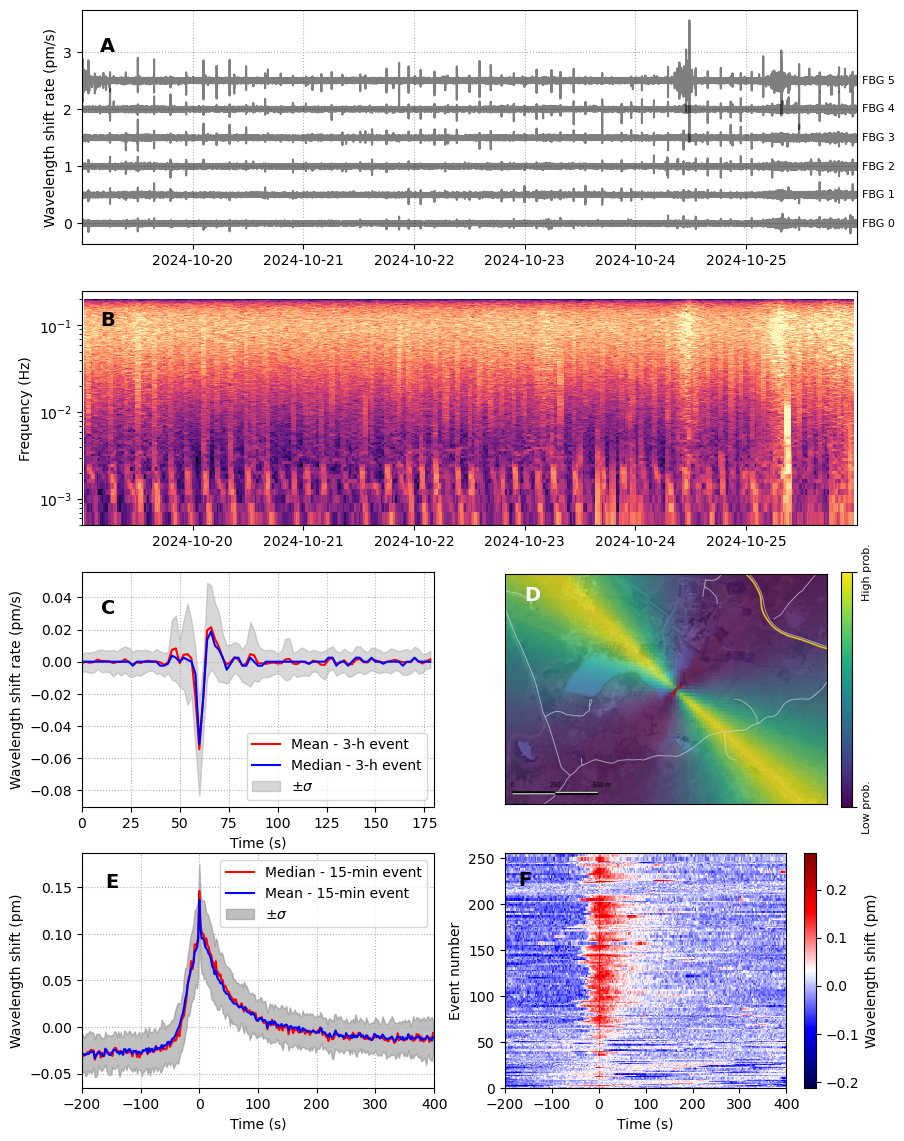

In [32]:
fig = plt.figure(figsize=(10,10*1.4))
ax1 = plt.subplot2grid((4,2), (0,0), colspan=2)
for i in range(grad.shape[0]):
    ax1.plot(dtrend_october.Time, grad[i,:]*1000+ i*0.5, color='k', alpha=0.5)
    ax1.text(dtrend_october.Time.values[-1] + pd.Timedelta(seconds=60*60), i*0.5, f'FBG {i}', va='center', ha='left', fontsize=8)
ax1.set_ylabel('Wavelength shift rate (pm/s)')
ax1.set_xlim(dtrend_october.Time.values[0].astype('datetime64[s]'), dtrend_october.Time.values[-1].astype('datetime64[s]'))
ax1.grid(ls=':')
ax2 = plt.subplot2grid((4,2), (1,0), colspan=2)
t0 = dtrend_october.Time.values[0].astype('datetime64[s]')
ax2.pcolormesh(t0 + t.astype(int),f,avg_Sxx, cmap='magma', vmin=np.nanpercentile(avg_Sxx, 1), vmax=np.nanpercentile(avg_Sxx, 99), shading='auto')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_yscale('log')
ax2.set_ylim(5e-4, .25)
ax2.set_xlim(dtrend_october.Time.values[0].astype('datetime64[s]'), dtrend_october.Time.values[-1].astype('datetime64[s]'))
#ax3 = plt.subplot2grid((3,2), (1,1), colspan=1)

#plt.fill_betweenx(np.arange(-0.5, 4.5, 1), np.datetime64('2024-10-19T11'), np.datetime64('2024-10-24T08'), color='orange', alpha=0.3)
#plt.title('Wavelength from 2024-10-18 to 2024-10-25\nCHANNEL 2, FBG 0 to 6 - Horizontal pads')
ax4 = plt.subplot2grid((4,2), (2,0), colspan=1)
ax4.plot(np.arange(len(aligned_events[0]))*2, np.mean(aligned_events, axis=0), color='r', label='Mean - 3-h event')
ax4.plot(np.arange(len(aligned_events[0]))*2, np.median(aligned_events, axis=0), color='b', label='Median - 3-h event')
ax4.fill_between(np.arange(len(aligned_events[0]))*2, np.mean(aligned_events, axis=0) - np.std(aligned_events, axis=0), np.mean(aligned_events, axis=0) + np.std(aligned_events, axis=0), color='grey', alpha=0.3, label='$\pm \sigma$')
ax4.legend(loc = 'lower right')
ax4.grid(ls=':')
ax4.set_xlabel('Time (s)')
ax4.set_xlim(0, len(aligned_events[0])*2)
ax4.set_ylabel('Wavelength shift rate (pm/s)')
ax5 = plt.subplot2grid((4,2), (2,1), colspan=1)
#ax5.imshow(np.sum(np.array(pair_beams), axis=0), cmap='viridis', extent=(-1000,1000,-1000,1000), origin='lower', alpha=1)
ax5.imshow(qgis_map,)
ax5.set_xticks([],[])
ax5.set_yticks([],[])
cbax5 = plt.colorbar(ScalarMappable(cmap='viridis', norm=mcolors.Normalize(vmin=0, vmax=1)), ax=ax5, orientation='vertical', fraction=0.046, pad=0.04)
cbax5.set_ticks([0, 1])
cbax5.set_ticklabels(['Low prob.', 'High prob.'], rotation=90, fontsize=8, va='center')
ax6 = plt.subplot2grid((4,2), (3,0), colspan=1)
aligned_15min_events = np.load(data_dir + '/aligned_events_15min_FBG_3.npy')
dt = 2
ax6.plot(np.arange(-100, 200)*dt,np.median(aligned_15min_events, axis=0), color='r', label='Median - 15-min event')
ax6.plot(np.arange(-100, 200)*dt,np.mean(aligned_15min_events, axis=0), color='b', label='Mean - 15-min event')
ax6.fill_between(np.arange(-100, 200)*dt, np.percentile(aligned_15min_events, 25, axis=0), np.percentile(aligned_15min_events, 75, axis=0), color='gray', alpha=0.5, label='$\pm \sigma$')
ax6.grid(ls=':')
ax6.set_xlim(-100*dt, 200*dt)
ax6.set_xlabel('Time (s)')
ax6.set_ylabel('Wavelength shift (pm)')
ax6.legend()
ax7 = plt.subplot2grid((4,2), (3,1), colspan=1)
ev15 = ax7.imshow(aligned_15min_events, cmap='seismic', aspect='auto', extent=[-100*dt, 200*dt, 0, aligned_15min_events.shape[0]])
ax7.set_xlabel('Time (s)')
ax7.set_ylabel('Event number')
plt.colorbar(ev15, ax=ax7, label='Wavelength shift (pm)')

ax1.text(dtrend_october.Time.values[0].astype('datetime64[s]') + pd.Timedelta(seconds=60*10*24), 3.0, 'A', fontsize=14, fontweight='bold', color='k')
ax2.text(dtrend_october.Time.values[0].astype('datetime64[s]') + pd.Timedelta(seconds=60*10*24), 0.1, 'B', fontsize=14, fontweight='bold', color='k')
ax4.text(10, 0.03, 'C', fontsize=14, fontweight='bold', color='k')
ax5.text(150, 200, 'D', fontsize=14, fontweight='bold', color='white')
ax6.text(-170 + 10, 0.15, 'E', fontsize=14, fontweight='bold', color='k')
ax7.text(-170, 220, 'F', fontsize=14, fontweight='bold', color='k')
plt.savefig(plot_dir + '/periodic_events_discussion.png', bbox_inches='tight', dpi=300)

plt.show()


## Proof of concept

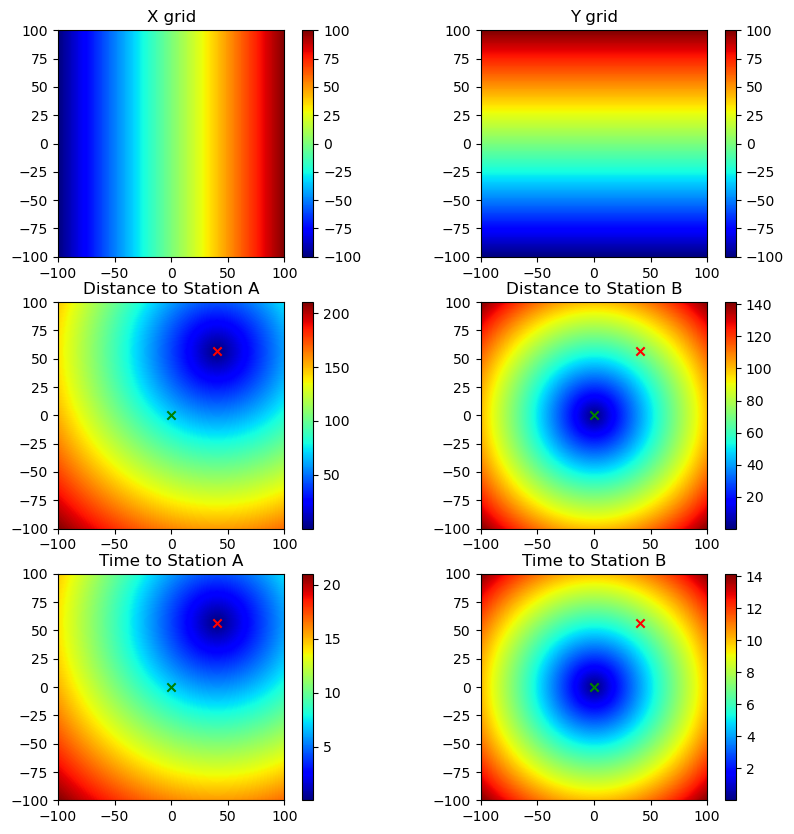

In [ ]:
diff = TimeGrid_stations((x[0], y[0]), (x[6], y[6]), 10, 
                  extent=(-100,100), res=1000, plot=True)

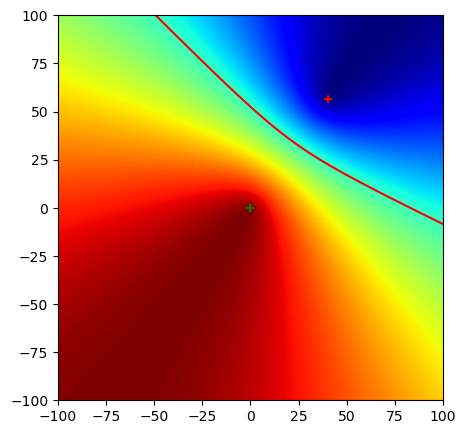

In [ ]:
plt.figure(figsize=(5,5))
plt.imshow(diff, cmap='jet', origin='lower', extent=(-100,100,-100,100))
plt.scatter(x[0], y[0], c='r', marker='+')
plt.scatter(x[6], y[6], c='g', marker='+')
plt.contour(X, Y, F, levels=[0], colors='r')
plt.show()